# 04 — Binary-sample quality control and finalization

**Purpose:** turn the full MIST output from Notebook 03 into a documented working sample for the planet-radius analysis.

This notebook:
1. checks the input table and identifier uniqueness;
2. computes the maximum absolute normalized residual for each system;
3. excludes systems with any absolute normalized residual greater than 5;
4. retains boundary-flagged systems unless they fail the residual cut;
5. writes the quality-controlled table and a separate exclusion table;
6. summarizes stellar densities and saves concise diagnostics;
7. maps the retained stellar systems to all their Sullivan 2024 planet rows and saves the final planet-level table.

The cut is a transparent working rule, not a claim that the retained sample is free of all systematic errors. Do not apply additional density-based cuts here.

**Input:** `data/processed/sullivan2024_joint_and_solar_mist_comparison.csv`

**Outputs:**
- `data/processed/sullivan2024_mist_quality_controlled.csv`
- `data/processed/sullivan2024_mist_excluded_poor_fits.csv`
- `data/processed/sullivan2024_mist_quality_control_summary.csv`
- `data/processed/sullivan2024_planets_quality_controlled.csv`
- `data/processed/sullivan2024_planets_in_excluded_systems.csv`
- `data/processed/sullivan2024_planet_mapping_summary.csv`


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path(".")
PROCESSED = ROOT / "data" / "processed"
INPUT_PATH = PROCESSED / "sullivan2024_joint_and_solar_mist_comparison.csv"

CLEAN_PATH = PROCESSED / "sullivan2024_mist_quality_controlled.csv"
EXCLUDED_PATH = PROCESSED / "sullivan2024_mist_excluded_poor_fits.csv"
SUMMARY_PATH = PROCESSED / "sullivan2024_mist_quality_control_summary.csv"

if not INPUT_PATH.exists():
    raise FileNotFoundError(
        f"Missing MIST output: {INPUT_PATH.resolve()}. Run Notebook 03 first."
    )

comparison = pd.read_csv(INPUT_PATH)
print("Input:", INPUT_PATH)
print("Rows:", len(comparison))
print("Columns:", len(comparison.columns))
display(comparison.head())


Input: data\processed\sullivan2024_joint_and_solar_mist_comparison.csv
Rows: 286
Columns: 59


,KOI,Rstar1,e_Rstar1,Rstar2,e_Rstar2,Teff1,e_Teff1,Teff2,e_Teff2,M1_16,...,rho2_joint_err_low,rho2_joint_err_high,M1_solar_iso_Msun,R1_solar_iso_Rsun,L1_solar_iso_Lsun,rho1_solar_iso_gcm3,M2_solar_iso_Msun,R2_solar_iso_Rsun,L2_solar_iso_Lsun,rho2_solar_iso_gcm3
0,42,1.376,0.009,0.710016,0.008301,6640,14,4771,38,1.289827,...,0.111047,0.110884,1.294106,1.324642,3.073397,0.699386,0.775751,0.708201,0.234173,3.051552
1,112,1.124,0.037,0.846372,0.029641,6256,61,5506,86,1.140198,...,0.234419,0.233562,1.159845,1.127725,1.755522,1.150015,0.934592,0.845431,0.591885,2.170406
2,162,1.078,0.053,0.874258,0.072361,6148,118,5622,188,1.050066,...,0.522497,0.518766,1.123569,1.076421,1.491348,1.262833,0.964719,0.877061,0.692419,2.032753
3,163,0.763,0.008,0.729428,0.008234,5290,55,5015,53,0.764319,...,0.319040,0.111918,0.883326,0.796123,0.447243,2.799948,0.827778,0.749232,0.319950,3.003097
4,165,0.850,0.028,0.656200,0.022420,5508,94,4432,79,0.906533,...,0.369523,0.371556,0.935117,0.845969,0.593511,2.143935,0.698699,0.651208,0.147454,3.481643


## 1. Validate identifiers and required fit diagnostics

In [2]:
required = {
    "KOI",
    "res_T1_joint", "res_R1_joint",
    "res_T2_joint", "res_R2_joint",
    "age_boundary", "feh_boundary",
    "fit_status",
}
missing = required - set(comparison.columns)
if missing:
    raise KeyError(
        f"Required columns are missing from the MIST output: {sorted(missing)}"
    )

comparison["KOI"] = pd.to_numeric(comparison["KOI"], errors="coerce")
if comparison["KOI"].isna().any():
    raise ValueError("Some KOI identifiers are missing or non-numeric.")
if comparison["KOI"].duplicated().any():
    duplicate_kois = comparison.loc[
        comparison["KOI"].duplicated(keep=False), "KOI"
    ].tolist()
    raise ValueError(f"Duplicate KOI systems found: {duplicate_kois[:10]}")

print("Unique KOI systems:", comparison["KOI"].nunique())
print("\nFit status:")
display(comparison["fit_status"].value_counts(dropna=False).to_frame("count"))


Unique KOI systems: 286

Fit status:


,count
fit_status,
OK,286


## 2. Apply the predefined residual-based quality cut

Each residual is normalized by its quoted observational uncertainty. We flag a system if **any** of its four normalized residuals has absolute value greater than 5.

Age or metallicity boundary flags are recorded but do not, by themselves, cause exclusion.


In [3]:
residual_cols = [
    "res_T1_joint",
    "res_R1_joint",
    "res_T2_joint",
    "res_R2_joint",
]

comparison[residual_cols] = comparison[residual_cols].apply(
    pd.to_numeric, errors="coerce"
)

comparison["max_abs_normalized_residual"] = comparison[residual_cols].abs().max(axis=1)
comparison["flag_missing_residual"] = comparison[residual_cols].isna().any(axis=1)
comparison["exclude_poor_fit"] = (
    comparison["flag_missing_residual"]
    | (comparison["max_abs_normalized_residual"] > 5.0)
)

comparison["boundary_flag"] = (
    comparison["age_boundary"].fillna(False).astype(bool)
    | comparison["feh_boundary"].fillna(False).astype(bool)
)

clean_sample = comparison.loc[~comparison["exclude_poor_fit"]].copy()
excluded_sample = comparison.loc[comparison["exclude_poor_fit"]].copy()

print("Original systems:", len(comparison))
print("Excluded for missing residuals or any |residual| > 5:", len(excluded_sample))
print("Retained systems:", len(clean_sample))
print("Boundary-flagged systems overall:", int(comparison["boundary_flag"].sum()))
print("Boundary-flagged systems retained:", int((clean_sample["boundary_flag"]).sum()))
print("Boundary-flagged systems excluded:", int((excluded_sample["boundary_flag"]).sum()))

display(
    excluded_sample[
        ["KOI", "chi2_min", "max_abs_normalized_residual",
         "age_boundary", "feh_boundary", "fit_status"]
    ].sort_values("max_abs_normalized_residual", ascending=False)
)


Original systems: 286
Excluded for missing residuals or any |residual| > 5: 8
Retained systems: 278
Boundary-flagged systems overall: 18
Boundary-flagged systems retained: 14
Boundary-flagged systems excluded: 4


,KOI,chi2_min,max_abs_normalized_residual,age_boundary,feh_boundary,fit_status
132,2535,381.942996,17.421897,False,False,OK
223,4580,356.248966,15.620068,False,True,OK
178,3112,276.373892,10.783460,True,False,OK
146,2705,194.851679,9.558782,False,False,OK
144,2664,146.690173,7.786983,True,False,OK
189,3263,61.272742,7.672275,False,False,OK
269,6475,53.339644,5.822571,False,True,OK
134,2542,73.502294,5.137265,False,False,OK


## 3. Check consistency of the reported minimum chi-square

For the current four-observable objective, the reported chi-square should equal the sum of the squared normalized residuals, up to numerical precision. This checks bookkeeping; it does not independently validate the stellar model.


In [4]:
if "chi2_min" in comparison.columns:
    comparison["chi2_from_residuals"] = (
        comparison[residual_cols] ** 2
    ).sum(axis=1, min_count=len(residual_cols))
    comparison["chi2_difference"] = (
        pd.to_numeric(comparison["chi2_min"], errors="coerce")
        - comparison["chi2_from_residuals"]
    )

    display(
        comparison[
            ["KOI", "chi2_min", "chi2_from_residuals", "chi2_difference"]
        ].assign(
            abs_difference=lambda x: x["chi2_difference"].abs()
        ).sort_values("abs_difference", ascending=False).head(10)
    )
else:
    print("chi2_min not present; skipped chi-square consistency check.")


,KOI,chi2_min,chi2_from_residuals,chi2_difference,abs_difference
269,6475,53.339644,53.339644,7.105427e-15,7.105427e-15
3,163,3.082442,3.082442,-8.881784e-16,8.881784e-16
108,2163,5.469360,5.469360,8.881784e-16,8.881784e-16
78,1899,7.814110,7.814110,-8.881784e-16,8.881784e-16
94,2031,2.585516,2.585516,-4.440892e-16,4.440892e-16
201,4032,2.162727,2.162727,-4.440892e-16,4.440892e-16
231,4823,3.312093,3.312093,-4.440892e-16,4.440892e-16
117,2376,1.262565,1.262565,4.440892e-16,4.440892e-16
187,3245,1.223673,1.223673,2.220446e-16,2.220446e-16
157,2879,1.579841,1.579841,2.220446e-16,2.220446e-16


## 4. Save the finalized sample and exclusion list

In [5]:
PROCESSED.mkdir(parents=True, exist_ok=True)

clean_sample.to_csv(CLEAN_PATH, index=False)
excluded_sample.to_csv(EXCLUDED_PATH, index=False)

summary = pd.DataFrame([{
    "input_systems": len(comparison),
    "retained_systems": len(clean_sample),
    "excluded_systems": len(excluded_sample),
    "residual_threshold_sigma": 5.0,
    "boundary_flagged_input": int(comparison["boundary_flag"].sum()),
    "boundary_flagged_retained": int(clean_sample["boundary_flag"].sum()),
    "boundary_flagged_excluded": int(excluded_sample["boundary_flag"].sum()),
}])
summary.to_csv(SUMMARY_PATH, index=False)

print("Saved:", CLEAN_PATH)
print("Saved:", EXCLUDED_PATH)
print("Saved:", SUMMARY_PATH)
display(summary)


Saved: data\processed\sullivan2024_mist_quality_controlled.csv
Saved: data\processed\sullivan2024_mist_excluded_poor_fits.csv
Saved: data\processed\sullivan2024_mist_quality_control_summary.csv


,input_systems,retained_systems,excluded_systems,residual_threshold_sigma,boundary_flagged_input,boundary_flagged_retained,boundary_flagged_excluded
0,286,278,8,5.0,18,14,4


## 5. Density summary for the retained sample

These are descriptive summaries only. Densities based on posterior-median mass and catalogue radius use
\[
\rho_\star = 1.408\,\frac{M/M_\odot}{(R/R_\odot)^3}\;\mathrm{g\,cm^{-3}}.
\]
No additional systems are removed based on density.


,count,mean,std,min,5%,25%,50%,75%,95%,max
rho1_joint_gcm3,278.0,2.200093,2.473564,0.601085,0.689098,1.143399,1.770240,2.543498,4.657566,35.822406
rho2_joint_gcm3,278.0,6.209827,15.116305,0.669693,1.294732,2.598953,3.499462,6.609839,15.312158,244.503374
rho1_solar_iso_gcm3,278.0,2.326647,4.120036,0.596813,0.696274,1.142280,1.824083,2.613419,4.693033,66.498436
rho2_solar_iso_gcm3,277.0,5.366035,4.793825,0.676922,1.294116,2.667044,3.553750,6.611519,14.004730,28.840102


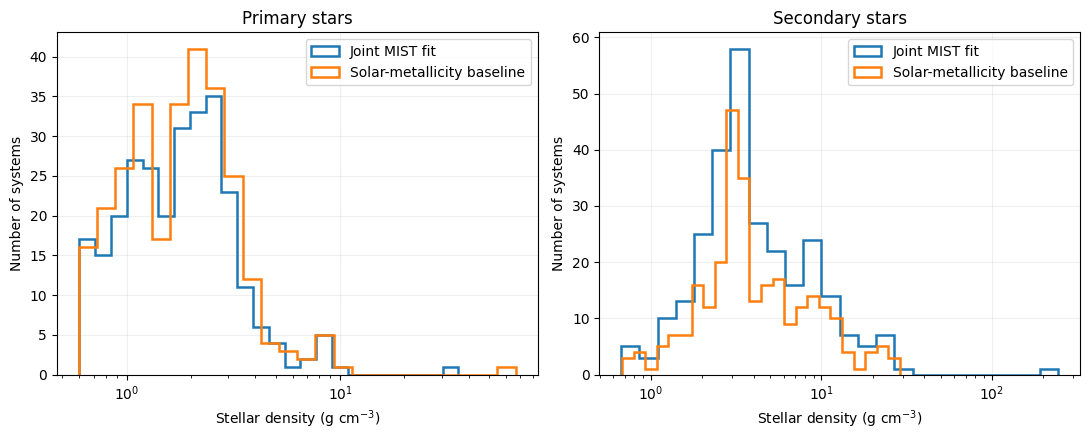

In [6]:
density_cols = [
    "rho1_joint_gcm3", "rho2_joint_gcm3",
    "rho1_solar_iso_gcm3", "rho2_solar_iso_gcm3",
]
available_density_cols = [c for c in density_cols if c in clean_sample.columns]

if available_density_cols:
    density_summary = clean_sample[available_density_cols].describe(
        percentiles=[0.05, 0.25, 0.50, 0.75, 0.95]
    ).T
    display(density_summary)

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    for ax, component, title in zip(
        axes, ["1", "2"], ["Primary stars", "Secondary stars"]
    ):
        joint_col = f"rho{component}_joint_gcm3"
        solar_col = f"rho{component}_solar_iso_gcm3"
        for col, label in [
            (joint_col, "Joint MIST fit"),
            (solar_col, "Solar-metallicity baseline"),
        ]:
            if col in clean_sample.columns:
                values = pd.to_numeric(clean_sample[col], errors="coerce")
                values = values[np.isfinite(values) & (values > 0)]
                if len(values):
                    ax.hist(values, bins=np.geomspace(values.min(), values.max(), 25),
                            histtype="step", linewidth=1.8, label=label)
        ax.set_xscale("log")
        ax.set_xlabel(r"Stellar density (g cm$^{-3}$)")
        ax.set_ylabel("Number of systems")
        ax.set_title(title)
        ax.grid(alpha=0.2)
        ax.legend()
    plt.tight_layout()
    plt.show()
else:
    print("No recognized density columns found; skipped density summary.")


## 6. Handoff to planet-radius analysis

Notebook 04 now writes `sullivan2024_planets_quality_controlled.csv`: one row per Sullivan planet whose host system passed the predefined MIST quality cut. It also saves the complete mapped planet table, planets in excluded systems, unmatched planets, and an audit summary. The final table retains binary metadata such as projected/angular separation when present in the Sullivan stellar table, plus the MIST results.

Keep the planet identifier `KOIpl` distinct from the system-level `KOI`. The three radius definitions (`Rpkep`, `Rppri`, `Rpsec`) are alternative estimates for the same planet, not three independent populations.

## 7. Map the full Sullivan planet table to the MIST results, then save the quality-controlled planet sample

This mapping is done at the planet-row level using system `KOI`. The map first attaches the full MIST fit/quality flag and then adds Sullivan stellar-catalogue columns that are not already in the MIST file (for example separation and photometric contrast). Every Sullivan planet row is retained in an audit table; the final science-ready table contains only planets whose host system passed the existing MIST residual cut. This avoids accidentally losing binary separation information needed for later analysis.

In [7]:
PLANET_PATH = ROOT / "data" / "raw" / "sullivan" / "sullivan_planet_table.csv"
STELLAR_CATALOGUE_PATH = ROOT / "data" / "raw" / "sullivan" / "sullivan_sample_table.csv"

ALL_PLANETS_MAPPED_PATH = PROCESSED / "sullivan2024_planets_with_mist_properties_all.csv"
FINAL_PLANETS_PATH = PROCESSED / "sullivan2024_planets_quality_controlled.csv"
EXCLUDED_PLANETS_PATH = PROCESSED / "sullivan2024_planets_in_excluded_systems.csv"
UNMATCHED_PLANETS_PATH = PROCESSED / "sullivan2024_planets_without_stellar_match.csv"
PLANET_MAPPING_SUMMARY_PATH = PROCESSED / "sullivan2024_planet_mapping_summary.csv"

for path in [PLANET_PATH, STELLAR_CATALOGUE_PATH]:
    if not path.exists():
        raise FileNotFoundError(
            f"Missing input: {path.resolve()}. Run Notebook 02 before Notebook 04."
        )

planet_catalogue = pd.read_csv(PLANET_PATH, dtype={"KOI": "string", "KOIpl": "string"})
stellar_catalogue = pd.read_csv(STELLAR_CATALOGUE_PATH, dtype={"KOI": "string"})

def normalize_system_koi(series):
    numeric = pd.to_numeric(series, errors="coerce")
    fractional = numeric.notna() & (~np.isclose(
        numeric, np.round(numeric), atol=1e-8, rtol=0.0
    ))
    if fractional.any():
        examples = series.loc[fractional].head(10).tolist()
        raise ValueError(f"Non-integer system KOI values: {examples}")
    return numeric.round().astype("Int64")

if not {"KOI", "KOIpl"}.issubset(planet_catalogue.columns):
    raise KeyError("Sullivan planet table must contain KOI and KOIpl.")
if "KOI" not in stellar_catalogue.columns:
    raise KeyError("Sullivan stellar table must contain KOI.")

planet_catalogue["KOI_key"] = normalize_system_koi(planet_catalogue["KOI"])
stellar_catalogue["KOI_key"] = normalize_system_koi(stellar_catalogue["KOI"])
comparison["KOI_key"] = normalize_system_koi(comparison["KOI"])

if stellar_catalogue["KOI_key"].duplicated().any():
    raise ValueError("Sullivan stellar table has duplicate system KOIs.")
if comparison["KOI_key"].duplicated().any():
    raise ValueError("MIST table has duplicate system KOIs.")
if planet_catalogue["KOIpl"].duplicated().any():
    raise ValueError("Sullivan planet table has duplicate KOIpl identifiers.")

# Add source-catalogue fields missing from the MIST output, preserving columns
# such as binary separation and contrast while avoiding duplicate radius/temperature fields.
extra_stellar_cols = [
    c for c in stellar_catalogue.columns
    if c not in {"KOI", "KOI_key"} and c not in comparison.columns
]
stellar_extras = stellar_catalogue[["KOI_key"] + extra_stellar_cols].copy()
comparison_for_merge = comparison.copy()

# Join raw stellar metadata one-to-one onto the all-system MIST table.
all_stars = comparison_for_merge.merge(
    stellar_extras, on="KOI_key", how="left", validate="one_to_one",
    indicator="_catalogue_match"
)
all_stars["catalogue_metadata_match"] = all_stars["_catalogue_match"].eq("both")
all_stars = all_stars.drop(columns="_catalogue_match")

# Merge planet-level rows to the full stellar/MIST table. `KOIpl` remains the planet ID.
planet_for_merge = planet_catalogue.rename(columns={"KOI": "KOI_planet_catalogue"})
stars_for_merge = all_stars.rename(columns={"KOI": "KOI_stellar_fit"})
mapped_all = planet_for_merge.merge(
    stars_for_merge, on="KOI_key", how="left", validate="many_to_one",
    indicator="_mist_match", suffixes=("_planet", "_stellar")
)
mapped_all.insert(0, "KOI", mapped_all["KOI_key"].astype("Int64"))
mapped_all["has_mist_match"] = mapped_all["_mist_match"].eq("both")
mapped_all = mapped_all.drop(columns="_mist_match")
mapped_all["passes_mist_quality_cut"] = (
    mapped_all["has_mist_match"]
    & ~mapped_all["exclude_poor_fit"].fillna(True).astype(bool)
)

final_planets = mapped_all.loc[mapped_all["passes_mist_quality_cut"]].copy()
excluded_planets = mapped_all.loc[
    mapped_all["has_mist_match"] & ~mapped_all["passes_mist_quality_cut"]
].copy()
unmatched_planets = mapped_all.loc[~mapped_all["has_mist_match"]].copy()

# Save both the complete mapping for audit and the quality-controlled handoff table.
PROCESSED.mkdir(parents=True, exist_ok=True)
mapped_all.to_csv(ALL_PLANETS_MAPPED_PATH, index=False)
final_planets.to_csv(FINAL_PLANETS_PATH, index=False)
excluded_planets.to_csv(EXCLUDED_PLANETS_PATH, index=False)
unmatched_planets.to_csv(UNMATCHED_PLANETS_PATH, index=False)

planet_summary = pd.DataFrame([
    {"metric": "input_stellar_systems_in_MIST_table", "value": len(comparison)},
    {"metric": "retained_stellar_systems", "value": len(clean_sample)},
    {"metric": "excluded_stellar_systems", "value": len(excluded_sample)},
    {"metric": "source_sullivan_planet_rows", "value": len(planet_catalogue)},
    {"metric": "source_unique_KOIpl", "value": planet_catalogue["KOIpl"].nunique()},
    {"metric": "all_planet_rows_mapped_or_flagged", "value": len(mapped_all)},
    {"metric": "planets_passing_MIST_quality_cut", "value": len(final_planets)},
    {"metric": "planets_in_excluded_systems", "value": len(excluded_planets)},
    {"metric": "planets_without_MIST_match", "value": len(unmatched_planets)},
    {"metric": "unique_systems_with_quality_controlled_planets", "value": final_planets["KOI"].nunique()},
    {"metric": "unique_systems_with_excluded_planets", "value": excluded_planets["KOI"].nunique()},
    {"metric": "unique_systems_without_MIST_match", "value": unmatched_planets["KOI"].nunique()},
])
planet_summary.to_csv(PLANET_MAPPING_SUMMARY_PATH, index=False)

print("Source Sullivan planet rows:", len(planet_catalogue))
print("All mapped rows:", len(mapped_all))
print("Planets mapped to quality-controlled systems:", len(final_planets))
print("Planets in excluded systems:", len(excluded_planets))
print("Planets with no MIST match:", len(unmatched_planets))
print("Unique retained systems with planets:", final_planets["KOI"].nunique())
print("\nSaved files:")
for path in [ALL_PLANETS_MAPPED_PATH, FINAL_PLANETS_PATH, EXCLUDED_PLANETS_PATH, UNMATCHED_PLANETS_PATH, PLANET_MAPPING_SUMMARY_PATH]:
    print(" -", path)
display(planet_summary)

preview_cols = [c for c in [
    "KOI", "KOIpl", "Sep", "Rpkep", "Rppri", "Rpsec",
    "M1_50", "M2_50", "rho1_joint_gcm3", "rho2_joint_gcm3",
    "passes_mist_quality_cut"
] if c in final_planets.columns]
display(final_planets[preview_cols].head(10))

# Row accounting and identifier integrity checks.
assert len(mapped_all) == len(planet_catalogue), (
    "The left join changed the source planet row count; inspect the join keys."
)
assert len(final_planets) + len(excluded_planets) + len(unmatched_planets) == len(planet_catalogue), (
    "Planet rows do not reconcile across the three output categories."
)
assert mapped_all["KOIpl"].nunique() == planet_catalogue["KOIpl"].nunique(), (
    "Some planet identifiers were lost or duplicated."
)
print("\nPlanet-to-star mapping checks passed.")

Source Sullivan planet rows: 404
All mapped rows: 404
Planets mapped to quality-controlled systems: 396
Planets in excluded systems: 8
Planets with no MIST match: 0
Unique retained systems with planets: 278

Saved files:
 - data\processed\sullivan2024_planets_with_mist_properties_all.csv
 - data\processed\sullivan2024_planets_quality_controlled.csv
 - data\processed\sullivan2024_planets_in_excluded_systems.csv
 - data\processed\sullivan2024_planets_without_stellar_match.csv
 - data\processed\sullivan2024_planet_mapping_summary.csv


,metric,value
0,input_stellar_systems_in_MIST_table,286
1,retained_stellar_systems,278
2,excluded_stellar_systems,8
3,source_sullivan_planet_rows,404
4,source_unique_KOIpl,404
5,all_planet_rows_mapped_or_flagged,404
6,planets_passing_MIST_quality_cut,396
7,planets_in_excluded_systems,8
8,planets_without_MIST_match,0
9,unique_systems_with_quality_controlled_planets,278


,KOI,KOIpl,Sep,Rpkep,Rppri,Rpsec,M1_50,M2_50,rho1_joint_gcm3,rho2_joint_gcm3,passes_mist_quality_cut
0,42,42.01,1.66,2.43,2.28,4.89,1.296510,0.774456,0.700686,3.046455,True
1,112,112.01,0.11,2.75,3.55,4.74,1.165363,0.937695,1.155487,2.177612,True
2,112,112.02,0.11,1.16,1.49,1.98,1.165363,0.937695,1.155487,2.177612,True
3,162,162.01,0.29,3.11,3.72,4.50,1.125737,0.962663,1.265270,2.028422,True
4,163,163.01,1.22,2.08,2.71,3.09,0.862757,0.814640,2.734749,2.955435,True
5,165,165.01,0.28,2.38,2.79,4.93,0.935768,0.700600,2.145429,3.491112,True
6,174,174.01,0.56,2.59,2.40,7.15,0.809408,0.346451,2.953764,13.874349,True
7,177,177.01,0.23,1.78,2.45,2.62,1.106245,1.050417,1.341670,1.563564,True
8,191,191.01,1.67,10.89,10.64,29.08,0.980909,0.575097,2.012917,5.355838,True
9,191,191.02,1.67,2.25,2.20,6.01,0.980909,0.575097,2.012917,5.355838,True



Planet-to-star mapping checks passed.
